# The DRAG trap: how qubits get stuck at zero, what it costs, and how to prevent it

## Overview

Sometimes calibrate_1q sets a qubit's X/2 DRAG coefficient to exactly zero and then can't move it away from zero. The gate then runs without DRAG for days or months. On Q26 this lasted from the 2025-03-20 code rollback to the 2026 thermal cycle. These episodes cause most of the frequency warnings that [D3a, section 2](d3a_calibrate_1q_ladders.ipynb) classes as "DRAG at zero".

**Hypothesis.** Qubits get stuck at DRAG zero because the first estimate after a reset falls outside the first window. The stuck episodes cost 1q RB, and a change to the reset would prevent them.

**Method.**

- Find the episodes in the calibration log and check them against DS2 (section 1).
- Compare 1q RB, the negative controls and the 2q gates before, during and after each episode (section 2).
- Replay the DRAG step from its payloads, to see how qubits reach zero and why they stay there (section 3).
- Replay alternative rules at each reset (section 4).
- Check which qubits are close to a reset under the current routine (section 5).
- Check whether heavy fRB censoring on other qubits comes from a frozen DRAG (section 6).

> **The DRAG step.** At the start of each run, a spec check sets DRAG to zero if it is out of range. Each XPi2Drag measurement then sweeps 21 DRAG values within $\pm L/N$ of the current value $d$, with $L = 5$ ns (drag_limit). It fits a straight line to each of two sequences and takes their crossing as the estimate $e$. The estimate can fall outside the sweep. The move in half-spans is
>
> $$k = \frac{e - d}{L/N},$$
>
> and the routine accepts the estimate if $|k| \le 1$. The ladder stops at the first $N$ that fails. The old code resets above 4 ns and runs $N = 1, 2, 4$. The new code (from 2025-02-17, apart from the 2025-03-20 to 2025-03-28 rollback) resets above 9 ns and runs $N = 2, 3, 4$. So the new code's first window is 2.5 ns instead of 5 ns. Section 3.1 checks both thresholds in the data.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import decode, periods
from qpu_drift.analysis import series
from qpu_drift.derived.run_map import load_run_entities, load_run_results
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.benchmarking import load_runs_l2
from qpu_drift.sources.benchmarking.constants import R2_GATE
from qpu_drift.sources.benchmarking.load import KPI_SUPPLEMENTED_PATH
from qpu_drift.sources.hardware_models import load_values
from qpu_drift.sources.measurements import load_measurements, local_payloads

pd.set_option("display.max_rows", 200, "display.max_columns", 30, "display.width", 250)

# Where the figure goes
FIG = REPO_ROOT / "docs" / "figures" / "hypotheses"
FIG.mkdir(parents=True, exist_ok=True)

# Analysis settings
WIN = pd.Timedelta("30D")  # before and after window, counted over usable runs
MIN_RUNS = 3  # episodes with fewer usable KPI runs before or inside are listed but not compared
NS = 1e9  # report DRAG in ns
PRE = 5  # runs before a reset used to describe the value it replaced
RECENT = pd.Timedelta("90D")  # look-back for the risk check in section 5

# KPI rows; usable means outside incidents and settling, kept means the fit passed the range and R2 check
kpi = pd.read_parquet(KPI_SUPPLEMENTED_PATH)
runs = load_runs_l2()
k = series.kpi_rows(kpi, runs)
k["usable"] = ~(k["incident"] | k["settling"])
kept = series.kept_kpi(k)

print(
    f"KPI rows {len(k):,}, kept {len(kept):,}, runs {k['run'].nunique():,}, "
    f"{k['t'].min():%Y-%m-%d} to {k['t'].max():%Y-%m-%d}; R2 gate {R2_GATE}"
)


KPI rows 104,800, kept 82,919, runs 655, 2024-05-24 to 2026-09-14; R2 gate 0.9


## 1. Episodes

An episode is a series of consecutive calibrate_1q runs that leave a qubit's X/2 DRAG at exactly zero. It ends at the next run that sets a non-zero value, or that starts from a non-zero value set outside the routine.

Each episode gets two shares. `measured` is the share of its runs that accepted a new DRAG value, and `warned` is the share that warned. They split the episodes into two kinds:

- **Stuck.** Most runs warn. The routine measures DRAG but rejects every estimate.
- **Silent.** Almost no run warns. The routine does not calibrate DRAG on that qubit.

`ds2_zero` is the share of the episode, within DS2 coverage, where the deployed model also holds zero. The last check lists DS2 zero intervals that no log episode covers.

In [2]:
# Every calibrate_1q DRAG row, in time order per qubit
ent = (
    load_run_entities(routine="calibrate_1q", param="drag")
    .sort_values(["qubit", "start"])
    .reset_index(drop=True)
)
DATA_END = ent["start"].max()
g = ent.groupby("qubit")

# Runs that leave zero, and values changed between runs outside calibrate_1q
ent["zero"] = ent["new"] == 0
prev_new = g["new"].shift()
ent["external"] = prev_new.notna() & (ent["old"] != prev_new)

# An episode opens at a zero run after a non-zero one, or after an external change
was_zero = g["zero"].shift(fill_value=False).astype(bool)
ent["opens"] = ent["zero"] & (~was_zero | ent["external"])
ent["ep"] = ent["opens"].cumsum().where(ent["zero"])
ent["next_start"] = g["start"].shift(-1)

# One row per episode; it ends at the start of the run after its last zero run
z = ent[ent["ep"].notna()]
EP = (
    z.groupby("ep")
    .agg(
        qubit=("qubit", "first"),
        start=("start", "min"),
        end=("next_start", "last"),
        runs=("start", "size"),
        drag_before_e9=("old", "first"),
        measured=("measured", "mean"),
        warned=("warned", lambda s: s.dropna().astype(float).mean() if s.notna().any() else np.nan),
    )
    .reset_index(drop=True)
)

# Episodes still open run to the end of the data
EP["open"] = EP["end"].isna()
EP["end"] = EP["end"].fillna(DATA_END)
EP["drag_before_e9"] *= 1e9

# DRAG set by the run that closed each episode
nxt = ent.set_index(["qubit", "start"])["new"]
EP["drag_after_e9"] = [
    nxt.get((r.qubit, r.end), np.nan) * 1e9 if not r.open else np.nan for r in EP.itertuples()
]
EP["days"] = ((EP["end"] - EP["start"]) / pd.Timedelta("1D")).round(1)

print(
    f"calibrate_1q DRAG rows: {len(ent):,}; leaving zero: {int(ent['zero'].sum()):,}; "
    f"episodes: {len(EP)}; "
    f"externally set values: {int(ent['external'].sum())}"
)

# DS2 cross-check: the deployed X/2 DRAG per qubit
v = load_values()
pat = r"quantum_devices\{Q(\d+)\}\.pulse_hw_x_pi_2\{drag\}$"
d = v[v["path"].str.extract(pat, expand=False).notna()].copy()
d["qubit"] = d["path"].str.extract(pat, expand=False).astype(int)
d["drag"] = d["value_float"].fillna(d["value_int"])

# DS2 coverage; intervals still open are closed at its end
DS2_SPAN = (d["valid_from_ts"].min(), max(d["valid_to_ts"].max(), d["valid_from_ts"].max()))
d["to"] = d["valid_to_ts"].fillna(DS2_SPAN[1])
dz = d[d["drag"] == 0]

print(
    f"DS2 x_pi_2 DRAG: {d['path'].nunique()} paths, "
    f"{DS2_SPAN[0]:%Y-%m-%d} to {DS2_SPAN[1]:%Y-%m-%d}; "
    f"zero intervals on qubits {sorted(dz['qubit'].unique().tolist())}"
)


def ds2_zero(r):
    """Share of episode r, within DS2 coverage, where DS2 also held zero."""
    lo, hi = max(r.start, DS2_SPAN[0]), min(r.end, DS2_SPAN[1])
    if hi <= lo:
        return np.nan

    # Zero intervals on this qubit that overlap the episode, clipped to it
    x = dz[(dz["qubit"] == r.qubit) & (dz["valid_from_ts"] < hi) & (dz["to"] > lo)]
    overlap = x["to"].clip(upper=hi) - x["valid_from_ts"].clip(lower=lo)
    cov = overlap.groupby(x["path"]).sum()

    # Use the best-covered path
    return cov.max() / (hi - lo) if len(cov) else 0.0


EP["ds2_zero"] = [ds2_zero(r) for r in EP.itertuples()]


def brk(t):
    """Breaks and incident starts within a day of t."""
    near = pd.Timedelta("1D")
    hits = [b.what for b in periods.BREAKS if abs(b.at - t) < near]
    hits += [f"incident: {i.what}" for i in periods.INCIDENTS if abs(i.period[0] - t) < near]
    return "; ".join(hits)


# What happened around each start and end, and stuck or silent
EP["start_near"] = EP["start"].map(brk)
EP["end_near"] = ["(open)" if r.open else brk(r.end) for r in EP.itertuples()]
EP["kind"] = np.where(EP["warned"].astype(float).fillna(0) > 0.5, "stuck", "silent")
display(EP.round(3))

# DS2 zero intervals whose start no log episode covers (one day of slack)
zd = dz[dz["valid_from_ts"] >= DS2_SPAN[0]]
miss = []
for r in zd.itertuples():
    covered = (
        (EP["qubit"] == r.qubit)
        & (EP["start"] <= r.valid_from_ts + pd.Timedelta("1D"))
        & (EP["end"] >= r.valid_from_ts)
    )
    if not covered.any():
        miss.append(r)

print(f"DS2 zero intervals not inside a log episode: {len(miss)}")

calibrate_1q DRAG rows: 41,536; leaving zero: 2,146; episodes: 17; externally set values: 364


DS2 x_pi_2 DRAG: 32 paths, 2025-01-01 to 2026-08-18; zero intervals on qubits [13, 16, 26, 27]


/tmp/ipykernel_17984/1822144677.py:104: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(EP.round(3))


,qubit,start,end,runs,drag_before_e9,measured,warned,open,drag_after_e9,days,ds2_zero,start_near,end_near,kind
0,2,2024-04-29 01:40:31,2024-09-18 15:13:54,22,-4.549,0.0,0.045,False,-1.027,142.6,NaN,,DS1 restore,silent
1,13,2024-04-16 23:15:04,2024-04-17 01:08:43,1,-5.195,0.0,<NA>,False,0.000,0.1,NaN,,,silent
2,13,2024-04-17 01:08:43,2024-10-16 03:51:42,34,-5.195,0.0,0.0,False,0.000,182.1,NaN,,,silent
3,13,2024-10-16 03:51:42,2025-03-19 08:00:20,261,-4.860,0.0,0.004,False,-4.081,154.2,0.989,,,silent
4,13,2025-03-20 12:00:58,2026-08-18 08:45:39,995,-4.081,0.0,0.001,False,0.000,515.9,1.000,calibrate_1q old code back,,silent
5,16,2025-02-13 08:00:21,2025-02-13 19:45:22,1,-4.604,0.0,1.0,False,-4.095,0.5,0.972,,,stuck
6,16,2025-02-14 08:00:20,2025-03-19 08:00:20,47,-4.095,0.0,0.957,False,-3.476,33.0,0.974,,,stuck
7,18,2024-04-16 23:15:04,2024-04-17 01:08:43,1,-4.210,0.0,<NA>,False,0.000,0.1,NaN,,,silent
8,18,2024-04-17 01:08:43,2024-04-17 05:36:04,1,-4.210,0.0,<NA>,False,0.160,0.2,NaN,,,silent
9,23,2024-04-16 23:15:04,2024-10-16 03:51:42,35,0.000,0.0,0.0,False,1.911,182.2,NaN,,,silent


DS2 zero intervals not inside a log episode: 0


**Results.**

- **Episodes.** The log has 17 episodes on qubits 2, 13, 16, 18, 23, 26 and 27.
- **DS2 agrees.** DS2 holds zero on Q13, Q16, Q26 and Q27, and every DS2 zero interval is inside a log episode. Where DS2 covers an episode, it holds zero for 0.87 or more of it. The one exception is a 1.9-day Q26 episode in 2026-03 (0.41).
- **Two long episodes.** Both start at the 2025-03-20 rollback. Q13 is silent for 515.9 days (995 runs, warned 0.001). Q26 is stuck for 354.3 days (705 runs, warned 0.989) and ends at the thermal cycle.
- **Silent episodes follow from the routine's set-up.** Q2 and Q13 have no XPi2Drag rows at all ([Phase 01, B3](../../docs/phases/01_eda.md#b3-ds1-measurements)), so the routine never calibrates their DRAG.
- **Short stuck episodes.** Q16 and Q27 have stuck episodes of 0.5 to 33 days in 2025-02 and 2025-03.

## 2. What the episodes cost

Each episode is compared with the same qubit before and after it. The before window is the last 30 days of usable runs before the episode, and the after window is the first 30 days of usable runs after it. Usable runs are outside incidents and settling. The other qubits in the same runs are the chip reference, and qubits with any episode are left out of it. An episode is compared only if it has at least 3 usable runs before and during it.

### 2.1 1q RB on the affected qubit

Each fRB row is ok (it passes the range and R² check), censored (it fails the check) or absent. The table gives these shares per window, with the median raw fidelity and the median R² as served before the check. The chip columns give the same shares for the other qubits in the same runs. The last table splits the longest stuck episode by quarter.

In [3]:
# Qubits with any episode stay out of the chip reference
EPQ = set(EP["qubit"])
EPQ_STR = [str(q) for q in EPQ]


def windows(x, r):
    """Split one element's usable rows into before, during and after episode r."""
    x = x[x["usable"]]

    # The last WIN of usable rows before the episode
    pre = x[x["t"] < r.start]
    if len(pre):
        pre = pre[pre["t"] >= pre["t"].max() - WIN]

    # The first WIN of usable rows after it
    post = x[x["t"] >= r.end]
    if len(post):
        post = post[post["t"] < post["t"].min() + WIN]

    during = x[(x["t"] >= r.start) & (x["t"] < r.end)]
    return {"before": pre, "during": during, "after": post}


def summ(x):
    """Row count, class shares and median raw value and R2."""
    return pd.Series(
        {
            "n": len(x),
            "ok": (x["cls"] == "ok").mean(),
            "censored": (x["cls"] == "censored").mean(),
            "absent": (x["cls"] == "absent").mean(),
            "F_med": x["value_u"].median(),
            "r2_med": x["r2_u"].median(),
        }
    )


# fRB per episode and window, next to the other qubits in the same runs
rb = k[k["metric"] == "fRB"]
rows = []
for r in EP.itertuples():
    me = rb[rb["element"] == str(r.qubit)]
    for w, x in windows(me, r).items():
        chip = rb[rb["run"].isin(x["run"]) & ~rb["element"].isin(EPQ_STR)]
        s = summ(x)
        rows.append(
            {
                "qubit": r.qubit,
                "start": r.start.date(),
                "kind": r.kind,
                "window": w,
                **s,
                "chip_ok": (chip["cls"] == "ok").mean(),
                "chip_censored": (chip["cls"] == "censored").mean(),
            }
        )
RB = pd.DataFrame(rows)

# Compare an episode only if it has MIN_RUNS usable runs before and during
RB["compared"] = RB.groupby(["qubit", "start"])["n"].transform(
    lambda s: min(s.iloc[0], s.iloc[1]) >= MIN_RUNS
)
display(RB.round(3))

# ok share before, during and after, compared episodes only
c = RB[RB["compared"]].pivot_table(
    index=["qubit", "start", "kind"], columns="window", values="ok", sort=False
)[["before", "during", "after"]]
print("\nok share, compared episodes:")
display(c.round(3))

# The longest stuck episode, quarter by quarter
r0 = EP.loc[EP["days"].where(EP["kind"] == "stuck").idxmax()]
x = rb[(rb["element"] == str(r0.qubit)) & rb["usable"] & (rb["t"] >= r0.start) & (rb["t"] < r0.end)]
print(f"\nQ{r0.qubit} by quarter inside its {r0.days:.0f}-day episode:")
display(x.groupby(x["t"].dt.to_period("Q")).apply(summ).round(3))

,qubit,start,kind,window,n,ok,censored,absent,F_med,r2_med,chip_ok,chip_censored,compared
0,2,2024-04-29,silent,before,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,2,2024-04-29,silent,during,75.0,0.000,0.000,1.000,0.992,NaN,0.000,0.001,False
2,2,2024-04-29,silent,after,20.0,0.850,0.050,0.100,0.996,0.991,0.890,0.034,False
3,13,2024-04-16,silent,before,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,13,2024-04-16,silent,during,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
5,13,2024-04-16,silent,after,26.0,0.000,0.000,1.000,0.980,NaN,0.000,0.002,False
6,13,2024-04-17,silent,before,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
7,13,2024-04-17,silent,during,76.0,0.013,0.000,0.987,0.980,0.973,0.013,0.001,False
8,13,2024-04-17,silent,after,20.0,0.950,0.000,0.050,0.981,0.973,0.890,0.034,False
9,13,2024-10-16,silent,before,1.0,1.000,0.000,0.000,0.992,0.973,0.960,0.040,False



ok share, compared episodes:


window                   before  during  after
qubit start      kind                         
13    2025-03-20 silent   1.000   0.874  0.750
16    2025-02-14 stuck    0.917   0.000  0.926
26    2025-03-20 stuck    0.950   0.003  0.821
27    2025-03-20 stuck    0.750   0.000  0.778
      2025-02-12 stuck    0.968   0.000  1.000


Q26 by quarter inside its 354-day episode:


,n,ok,censored,absent,F_med,r2_med
t,,,,,,
2025Q1,11.0,0.091,0.909,0.000,0.772,0.586
2025Q2,88.0,0.000,0.943,0.057,0.784,0.622
2025Q3,83.0,0.000,0.940,0.060,0.783,0.634
2025Q4,86.0,0.000,0.884,0.116,0.781,0.627
2026Q1,56.0,0.000,0.946,0.054,0.773,0.634


**Results.**

- **Stuck episodes break 1q RB.** In each compared stuck episode, the ok share falls to 0.003 or less, from 0.75 to 0.97 before. It recovers to 0.78 to 1.00 after. The other qubits stay at 0.83 to 0.91 in the same runs. The Q16 and Q27 episodes have only 5 to 18 rows during, so most of the evidence comes from Q26.
- **The fits fail because the gate is bad.** During Q26's episode, 0.926 of its rows are censored, with a median raw fidelity of 0.780 and a median R² of 0.630. Its ok share is at most 0.091 in every quarter.
- **The silent Q13 episode costs little.** Its ok share is 0.874 during the episode, against 1.000 before and 0.750 after. The other qubits are at 0.827 in the same runs.

### 2.2 Negative controls

This uses kept rows only. For each run, it takes the qubit's $\log_{10}$ value minus the median $\log_{10}$ value of the other qubits in the same run. This removes chip-wide shifts:

$$\text{rel} = \log_{10} x_{q} - \operatorname{median}_{j \ne q} \log_{10} x_{j}.$$

Here $x$ is the infidelity for fRO and fRB, and the time in µs for T1 and T2. DRAG only shapes the drive pulse, so T1, T2 and fRO should not change during an episode. fRB is shown for completeness, but most of its rows are censored during the stuck episodes.

In [4]:
# Chip median of the log10 value per metric and run, over qubits with no episode
is_metric = kept["metric"].isin(["fRB", "fRO", "T1", "T2"])
oth = kept[~kept["element"].isin(EPQ_STR) & is_metric]
chip_med = oth.groupby(["metric", "run"])["lx"].median().rename("chip_lx")

# Each row relative to its chip median
rel = kept[is_metric].join(chip_med, on=["metric", "run"])
rel["rel"] = rel["lx"] - rel["chip_lx"]

# Median relative level per episode, metric and window
rows = []
for r in EP.itertuples():
    for m in ["T1", "T2", "fRO", "fRB"]:
        me = rel[(rel["metric"] == m) & (rel["element"] == str(r.qubit))]
        for w, x in windows(me, r).items():
            rows.append(
                {
                    "qubit": r.qubit,
                    "start": r.start.date(),
                    "metric": m,
                    "window": w,
                    "n": len(x),
                    "rel_med": x["rel"].median(),
                    "value_med": (10 ** x["lx"]).median(),
                }
            )
REL = pd.DataFrame(rows)

# Keep the episodes compared in section 2.1
compared = RB.loc[RB["compared"]].set_index(["qubit", "start"]).index
REL = REL[REL.set_index(["qubit", "start"]).index.isin(compared)]

# Levels before, during and after, and how far they shift
tb = REL.pivot_table(
    index=["qubit", "start", "metric"], columns="window", values=["rel_med", "n"], sort=False
)
tb = tb.reindex(
    columns=pd.MultiIndex.from_product([["rel_med", "n"], ["before", "during", "after"]])
)
tb[("shift", "during-before")] = tb[("rel_med", "during")] - tb[("rel_med", "before")]
tb[("shift", "after-during")] = tb[("rel_med", "after")] - tb[("rel_med", "during")]

print(
    "chip-relative log10 level (fRO, fRB: infidelity; T1, T2: µs); positive = higher than chip median"
)
display(tb.round(3))

chip-relative log10 level (fRO, fRB: infidelity; T1, T2: µs); positive = higher than chip median


rel_med                    n                      shift             
                         before during  after before during after during-before after-during
qubit start      metric                                                                     
13    2025-03-20 T1      -0.126 -0.180 -0.135   20.0  433.0  16.0        -0.054        0.045
                 T2      -0.571 -0.771 -0.675    9.0  430.0  16.0        -0.199        0.096
                 fRO      0.530  0.477  0.249   20.0  433.0  16.0        -0.053       -0.227
                 fRB      0.892  0.944  0.761   20.0  381.0  12.0         0.052       -0.183
16    2025-02-14 T1      -0.024    NaN -0.209   29.0    0.0  27.0           NaN          NaN
                 T2      -0.158    NaN    NaN   22.0    0.0   0.0           NaN          NaN
                 fRO      0.704  0.858  0.782   24.0   18.0  27.0         0.154       -0.076
                 fRB      0.203    NaN  0.323   30.0    0.0  25.0           NaN          NaN
26    2025-03-20 T1       0.050  0.093  0.013   19.0  290.0  28.0         0.043       -0.080
                 T2       0.269  0.047 -0.109   20.0  128.0  28.0        -0.222       -0.156
                 fRO      0.005  0.104  0.170   20.0  324.0  28.0         0.099        0.067
                 fRB      0.036  1.233 -0.166   19.0    1.0  23.0         1.197       -1.399
27    2025-03-20 T1       0.085  0.146  0.052   20.0    5.0  25.0         0.060       -0.094
                 T2       0.450  0.364  0.181   17.0    1.0  23.0        -0.086       -0.183
                 fRO     -0.197  0.060 -0.085   20.0    6.0  25.0         0.257       -0.145
                 fRB     -0.023    NaN -0.124   15.0    0.0  24.0           NaN          NaN
      2025-02-12 T1      -0.004  0.083  0.087   27.0    5.0  15.0         0.087        0.003
                 T2       0.403  0.511  0.399   13.0    4.0  13.0         0.108       -0.112
                 fRO     -0.109 -0.081 -0.216   31.0    5.0  15.0         0.028       -0.135
                 fRB     -0.055    NaN -0.023   30.0    0.0  15.0           NaN          NaN

**Results.** All shifts are in $\log_{10}$ units, during minus before unless stated.

- **T1 holds.** T1 shifts by −0.054 on Q13 and +0.043 on Q26.
- **Q26's T2 falls, but not because of the episode.** It falls by 0.222 during the episode (128 rows) and by another 0.156 after it.
- **Q13's T2 is low throughout.** It is 0.57 to 0.77 below the chip in every window.
- **fRO rises a little in the stuck episodes.** The shift is +0.099 on Q26, +0.154 on Q16 (18 rows) and +0.257 on Q27 (6 rows). So fRO may not be a clean control: if its measurement prepares the excited state with the same drive pulse, a bad pulse can raise it.
- **Q16 has no T1 or T2 rows during its episode.**

### 2.3 2q gates on the affected couplings

This repeats section 2.1 for fCX on the couplings that include an episode qubit. `role` says whether the qubit is the control (first index) or the target. The chip columns cover couplings with no episode qubit, in the same runs.

In [5]:
# fCX rows, with the two qubits of each coupling split out
cx = k[k["metric"] == "fCX"].copy()
ab = cx["element"].str.split("-", expand=True)
cx["a"], cx["b"] = ab[0], ab[1]

# Chip reference: couplings with no episode qubit
no_ep = ~cx["a"].isin(EPQ_STR) & ~cx["b"].isin(EPQ_STR)

# Every coupling on an episode qubit, per window
rows = []
for r in EP.itertuples():
    q = str(r.qubit)
    on_q = (cx["a"] == q) | (cx["b"] == q)
    for el in sorted(cx.loc[on_q, "element"].unique()):
        me = cx[cx["element"] == el]
        role = "control" if me["a"].iloc[0] == q else "target"
        for w, x in windows(me, r).items():
            chip = cx[cx["run"].isin(x["run"]) & no_ep]
            rows.append(
                {
                    "qubit": r.qubit,
                    "start": r.start.date(),
                    "coupling": el,
                    "role": role,
                    "window": w,
                    **summ(x),
                    "chip_ok": (chip["cls"] == "ok").mean(),
                    "chip_F_med": chip["value_u"].median(),
                }
            )
CX = pd.DataFrame(rows)

# Keep the episodes compared in section 2.1
CX = CX[CX.set_index(["qubit", "start"]).index.isin(compared)]
display(CX.round(3))

,qubit,start,coupling,role,window,n,ok,censored,absent,F_med,r2_med,chip_ok,chip_F_med
27,13,2025-03-20,12-13,target,before,20.0,0.950,0.050,0.000,0.886,0.975,0.992,0.969
28,13,2025-03-20,12-13,target,during,436.0,0.995,0.000,0.005,0.944,0.993,0.903,0.973
29,13,2025-03-20,12-13,target,after,16.0,1.000,0.000,0.000,0.944,0.993,0.663,0.962
30,13,2025-03-20,13-14,control,before,20.0,1.000,0.000,0.000,0.919,0.982,0.992,0.969
31,13,2025-03-20,13-14,control,during,436.0,0.979,0.016,0.005,0.896,0.967,0.903,0.973
32,13,2025-03-20,13-14,control,after,16.0,1.000,0.000,0.000,0.919,0.976,0.663,0.962
39,16,2025-02-14,17-16,target,before,24.0,0.958,0.042,0.000,0.968,0.997,0.958,0.972
40,16,2025-02-14,17-16,target,during,18.0,0.444,0.556,0.000,0.906,0.857,0.991,0.969
41,16,2025-02-14,17-16,target,after,27.0,1.000,0.000,0.000,0.946,0.994,0.973,0.971
42,16,2025-02-14,7-16,target,before,24.0,0.958,0.042,0.000,0.976,0.997,0.958,0.972


**Results.**

- **Couplings on Q16 and Q26 suffer.** The ok share before, during and after is 0.958, 0.444 and 1.000 on 17-16, and 0.958, 0.500 and 1.000 on 7-16. On 26-25 it is 1.000, 0.790 and 1.000, and its median raw fidelity falls from 0.964 to 0.883. On 26-35 it is 1.000 and 0.907, with no rows after.
- **Couplings on Q13 and Q27 don't.** Their ok share stays at 0.95 or more in every window.

## 3. How qubits get trapped

### 3.1 Replaying the DRAG step

This decodes every XPi2Drag payload from calibrate_1q. For each run, qubit and $N$, the payload gives the current value $d$ and the estimate $e$. Acceptance follows from $|k| \le 1$. Two checks against the log test the replay:

- **Within a run,** each $N$ should start from the last accepted value.
- **At the end of a run,** the final DRAG should equal the log value.

The cell also shows the first $N$ in use per quarter, the reset threshold seen in the data, and how far estimates move in normal operation.

In [6]:
t0 = time.time()

# Valid calibrate_1q DRAG results and their measurement file paths
rr = load_run_results()
rq = rr[(rr["routine"] == "calibrate_1q") & rr["valid"] & (rr["step"] == "drag")]
meas = load_measurements()[["id", "relative_filepath"]]

# Map each relative path to a local raw file (the first root wins)
paths = local_payloads()

ids = rq.drop_duplicates("result_id").merge(meas, left_on="result_id", right_on="id", how="left")
ids["path"] = ids["relative_filepath"].map(paths)

# One row per payload and qubit: N, drag_limit, current value and estimate
rows, bad = [], 0
for x in ids.dropna(subset=["path"]).itertuples():
    try:
        obj = decode.payload(x.path)
    except decode.PayloadError:
        bad += 1
        continue

    cfg = decode.plain(obj["dict"]["config"])
    for key, tg in decode.iter_targets(obj):
        est = tg.get("new_drag")
        rows.append(
            {
                "start": x.start,
                "qubit": int(key[1:]),
                "N": int(cfg["N"]),
                "lim": cfg["drag_limit"],
                "old": cfg["old_drags"][key],
                "est": float(est) if est is not None else np.nan,
            }
        )

# One row per qubit, run and N, in ladder order
D = (
    pd.DataFrame(rows)
    .sort_values(["qubit", "start", "N"])
    .drop_duplicates(["qubit", "start", "N"], ignore_index=True)
)

# The move k in half-spans, and what the routine does with it
D["half"] = D["lim"] / D["N"]
D["k"] = (D["est"] - D["old"]) / D["half"]
D["acc"] = D["k"].abs() <= 1
D["after"] = np.where(D["acc"], D["est"], D["old"])

print(
    f"payloads {len(ids):,} ({ids['path'].isna().sum()} missing, {bad} unreadable); "
    f"rows {len(D):,}; "
    f"{D['start'].min():%Y-%m-%d} to {D['start'].max():%Y-%m-%d}; {time.time() - t0:.0f} s"
)

# Check 1: each N starts from the value the previous N left
gd = D.groupby(["qubit", "start"])
nx = gd["old"].shift(-1)
m = nx.notna()
same_start = np.isclose(nx[m], D.loc[m, "after"], rtol=0, atol=1e-15)
print(f"next N starts from the last accepted value: {same_start.mean():.4f} of {m.sum():,}")

# One row per run and qubit, joined to the log
RUN = gd.agg(
    Ns=("N", tuple),
    N1=("N", "first"),
    start_val=("old", "first"),
    e0=("est", "first"),
    k0=("k", "first"),
    acc0=("acc", "first"),
    final=("after", "last"),
    any_acc=("acc", "any"),
).reset_index()
RUN = RUN.merge(
    ent[["start", "qubit", "old", "new", "measured", "warned", "external"]],
    on=["start", "qubit"],
    how="inner",
)

# Check 2: the replay ends where the log does
final_match = np.isclose(RUN["final"], RUN["new"], rtol=0, atol=1e-15).mean()
measured_match = (RUN["any_acc"] == RUN["measured"].astype(bool)).mean()
print(
    f"runs x qubits matched to the log: {len(RUN):,}; final DRAG = log value: {final_match:.4f}; "
    f"accepted any = log 'measured': {measured_match:.4f}"
)

# Which ladder was in use, by quarter
RUN["quarter"] = RUN["start"].dt.to_period("Q").astype(str)
print("\nfirst N of the DRAG ladder by quarter (runs x qubits):")
display(
    RUN.pivot_table(index="quarter", columns="N1", values="qubit", aggfunc="size", fill_value=0)
)

# A reset: the run starts from zero although the log had a non-zero value before it
RUN["reset"] = (RUN["start_val"] == 0) & (RUN["old"] != 0)
nr = RUN[~RUN["reset"] & (RUN["old"] != 0)]
reset_runs = RUN[RUN["reset"]]

# The threshold sits between the largest value kept and the smallest value reset
print("\nreset threshold seen in the data (|DRAG| at the start of the run, ns):")
thresholds = pd.DataFrame(
    {
        "largest kept": nr.groupby("N1")["old"].apply(lambda s: s.abs().max() * NS),
        "smallest reset": reset_runs.groupby("N1")["old"].apply(lambda s: s.abs().min() * NS),
        "resets": reset_runs.groupby("N1").size(),
    }
)
display(thresholds.round(2))

# How far estimates move, and how often they're accepted, when not starting from zero
print("\nmove k (in half-spans) and acceptance in normal operation (start value not zero):")
nz = D[D["old"] != 0]
display(
    nz.groupby("N")
    .agg(
        rows=("k", "size"),
        accept=("acc", "mean"),
        k05=("k", lambda s: s.quantile(0.05)),
        k50=("k", "median"),
        k95=("k", lambda s: s.quantile(0.95)),
    )
    .round(3)
)

payloads 7,396 (0 missing, 0 unreadable); rows 108,216; 2024-09-18 to 2026-08-18; 17 s
next N starts from the last accepted value: 1.0000 of 71,434


runs x qubits matched to the log: 36,782; final DRAG = log value: 1.0000; accepted any = log 'measured': 1.0000

first N of the DRAG ladder by quarter (runs x qubits):


N1,1,2,3
quarter,,,
2024Q3,58,0,0
2024Q4,3973,0,0
2025Q1,2929,1410,0
2025Q2,0,5216,0
2025Q3,0,5460,0
2025Q4,0,5430,0
2026Q1,0,4406,0
2026Q2,0,5190,16
2026Q3,0,2694,0



reset threshold seen in the data (|DRAG| at the start of the run, ns):


,largest kept,smallest reset,resets
N1,,,
1,4.00,4.00,111.0
2,8.51,9.12,3.0
3,3.34,NaN,NaN



move k (in half-spans) and acceptance in normal operation (start value not zero):


,rows,accept,k05,k50,k95
N,,,,,
1,6799,0.999,-0.241,-0.068,0.053
2,35986,0.995,-0.363,-0.019,0.127
3,28912,0.996,-0.125,0.035,0.307
4,35637,0.994,-0.125,0.057,0.562


**Results.**

- **The replay is exact.** Each $N$ starts from the last accepted value on all 71,434 steps. The final DRAG equals the log value on all 36,782 run and qubit pairs.
- **The ladder changes in 2025Q1.** The first $N$ is 1 up to 2025Q1 and 2 from 2025Q2. Only 16 rows, in 2026Q2, start at $N = 3$.
- **The thresholds are 4 ns and 9 ns.** With $N = 1$ first, the largest value kept and the smallest value reset are both 4.00 ns (111 resets). With $N = 2$ first, the largest value kept is 8.51 ns and the smallest value reset is 9.12 ns (3 resets).
- **Normal operation rarely rejects.** When a run does not start from zero, 0.994 to 0.999 of steps are accepted. The 5th to 95th percentile of $k$ lies between −0.36 and 0.56 for every $N$.

### 3.2 Resets, and which ones become traps

A reset is a run whose first DRAG step starts from zero although the log holds a non-zero value just before it. This means the spec check fired. For each reset, the table gives:

- the value it replaced, and the median and first-step acceptance of the 5 runs before it,
- the first estimate from zero $e_0$ and its move $k_0$.

A reset **escaped in the run** if the same run ends with a non-zero DRAG. Otherwise it is **trapped**. For a trapped reset, the table gives the runs and days at zero, and how the episode ended: a later calibrate_1q run, a value set outside the routine, or still open.

> **The $|k_0| > 1$ split is a check, not a finding.** A first step with $|k_0| > 1$ is rejected and the ladder stops, so the run ends at zero. So $|k_0| > 1$ separates trapped from escaped resets by construction. The real questions are which resets get there, and why later runs stay at zero (section 3.3).

In [7]:
# Follow each reset forward to its exit
RUN = RUN.sort_values(["qubit", "start"], ignore_index=True)
out = []
for r in RUN[RUN["reset"]].itertuples():
    q = RUN[RUN["qubit"] == r.qubit]
    before = q[q["start"] < r.start].tail(PRE)
    later = q[q["start"] >= r.start]

    # The exit is the first later run with a non-zero DRAG (None if still stuck)
    nzv = later[later["new"] != 0]
    ex = nzv.iloc[0] if len(nzv) else None

    # Runs spent at zero, and when the stretch ends
    zero = later[later["start"] < ex["start"]] if ex is not None else later
    exit_t = ex["start"] if ex is not None else q["start"].max()

    # How it got out
    if ex is None:
        exit_how = "open"
    elif ex["external"]:
        exit_how = "set externally"
    else:
        exit_how = "calibrate_1q"

    out.append(
        {
            "qubit": r.qubit,
            "start": r.start,
            "ladder": r.Ns[0],
            "replaced": r.old * NS,
            "before_med": before["new"].median() * NS,
            "before_acc": before["any_acc"].mean(),
            "e0": r.e0 * NS,
            "k0": r.k0,
            "runs_at_zero": len(zero),
            "days": (exit_t - r.start) / pd.Timedelta("1D"),
            "exit": exit_how,
            "exit_val": np.nan if ex is None else ex["new"] * NS,
        }
    )
RS = pd.DataFrame(out)
RS["outcome"] = np.where(RS["runs_at_zero"] == 0, "escaped in the run", "trapped")
print(f"resets: {len(RS)} on {RS['qubit'].nunique()} qubits")

# Resets per ladder and outcome, with the range of first-step moves
display(
    RS.groupby(["ladder", "outcome"])
    .agg(
        resets=("qubit", "size"),
        qubits=("qubit", "nunique"),
        abs_k0_max=("k0", lambda s: s.abs().max()),
        abs_k0_min=("k0", lambda s: s.abs().min()),
        runs_at_zero=("runs_at_zero", "sum"),
    )
    .round(2)
)

# Does a first step beyond one half-span separate trapped from escaped?
splits = (RS["k0"].abs() > 1) == (RS["outcome"] == "trapped")
print(f"first-step |k0| > 1 separates trapped from escaped: {splits.mean():.3f}")

# Every trapped reset, plus everything under the current ladder
print("\ntrapped resets, and all resets since 2025-03-28 (current ladder):")
display(RS[(RS["outcome"] == "trapped") | (RS["start"] >= "2025-03-28")].round(2))

resets: 114 on 8 qubits


resets  qubits  abs_k0_max  abs_k0_min  runs_at_zero
ladder outcome                                                                 
1      escaped in the run     105       5        0.97        0.00             0
       trapped                  6       3       14.72        1.02           773
2      escaped in the run       3       2        0.30        0.02             0

first-step |k0| > 1 separates trapped from escaped: 1.000

trapped resets, and all resets since 2025-03-28 (current ladder):


/tmp/ipykernel_17984/1354241645.py:64: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(RS[(RS["outcome"] == "trapped") | (RS["start"] >= "2025-03-28")].round(2))


,qubit,start,ladder,replaced,before_med,before_acc,e0,k0,runs_at_zero,days,exit,exit_val,outcome
34,16,2025-02-13 08:00:21,1,-4.60,-3.09,1.0,-5.09,-1.02,1,0.49,calibrate_1q,-4.09,trapped
35,16,2025-02-14 08:00:20,1,-4.09,-3.11,0.8,-6.53,-1.31,45,33.00,set externally,-3.48,trapped
106,26,2025-03-20 12:00:58,1,-4.28,-3.81,1.0,-73.59,-14.72,697,354.32,calibrate_1q,1.24,trapped
107,26,2026-07-05 08:45:41,2,-9.29,-7.35,0.8,-0.76,-0.30,0,0.00,calibrate_1q,-1.98,escaped in the run
108,27,2025-02-12 19:45:29,1,-4.99,-2.86,1.0,-5.60,-1.12,10,4.77,set externally,-5.27,trapped
109,27,2025-03-20 12:00:58,1,-6.67,-3.72,0.8,-9.50,-1.90,18,8.32,set externally,-4.75,trapped
110,27,2025-03-27 19:44:13,1,-4.78,0.00,0.0,-10.22,-2.04,2,1.00,set externally,-4.75,trapped


**Results.**

- **Resets.** There are 114 resets on 8 qubits. 111 happen under the old code ($N = 1$ first, 4 ns threshold), and 3 under the new code ($N = 2$ first, 9 ns threshold).
- **All 6 traps start under the old code.** They are on Q16, Q26 and Q27, and spend 773 runs at zero in total. Five of them follow normal runs with a median DRAG of −2.86 to −3.81 ns, within 1.2 ns of the 4 ns threshold. The sixth (Q27, 2025-03-27) comes straight after another Q27 trap.
- **Traps outlast the code change.** Q26's 2025-03-20 reset has $e_0 = -73.59$ ns ($k_0 = -14.72$). It stays at zero for 697 runs over 354.3 days, almost all of them under the new code. Q16's 2025-02-14 trap also continues past the 2025-02-17 code change. So the new code does not release a qubit that is already at zero.
- **How traps end.** Q26's trap ends at the thermal cycle, at +1.24 ns, the opposite sign to before. Four of the other five end with a value set outside the routine.
- **The new code's resets.** All 3 escape in the run. Q26's 2026-07-05 reset replaced −9.29 ns, but its first estimate from zero is only −0.76 ns ($k_0 = -0.30$). The run ends at −1.98 ns, against −7.35 ns before. So escaping does not mean the qubit returns to its value.

### 3.3 What the routine measures at zero

While a qubit is at zero, each run measures the first step from zero again, and rejects it. If these estimates pointed at the qubit's real DRAG, a wider first window would release it. The table compares the estimates from zero inside each trap with the median value before the reset, and with the median of the 20 runs after the trap ends. The last line does the same for the escaped resets, as the first estimate from zero divided by the value it replaced.

In [8]:
rows = []
for r in RS[RS["outcome"] == "trapped"].itertuples():
    q = RUN[RUN["qubit"] == r.qubit]
    end = r.start + pd.Timedelta(days=r.days)

    # Estimates from zero inside the trapped stretch
    inside = D[
        (D["qubit"] == r.qubit) & (D["start"] >= r.start) & (D["start"] < end) & (D["old"] == 0)
    ]

    # Where the qubit settled: the 20 runs after the exit
    after = q[q["start"] >= end].head(20)["new"]

    # Spread of the estimates per N, next to the values before and after
    for n, x in inside.groupby("N"):
        e = x["est"] * NS
        rows.append(
            {
                "qubit": r.qubit,
                "reset": r.start,
                "N": n,
                "runs": len(x),
                "est_p10": e.quantile(0.1),
                "est_med": e.median(),
                "est_p90": e.quantile(0.9),
                "half_span": 5 / n,
                "before": r.before_med,
                "settled_after": after.median() * NS,
                "same_sign_as_before": float(np.sign(e.median()) == np.sign(r.before_med)),
            }
        )
E3 = pd.DataFrame(rows)
display(E3.round(2))

# Escaped resets: the first estimate from zero as a share of the value it replaced
ok = RS[(RS["outcome"] == "escaped in the run")]
ratio = ok["e0"] / ok["replaced"]
print(
    f"\nescaped resets ({len(ok)}): first estimate from zero as a share of the value it replaced, "
    f"median {np.median(ratio):.2f}, "
    f"IQR [{np.quantile(ratio, 0.25):.2f}, {np.quantile(ratio, 0.75):.2f}]"
)

/tmp/ipykernel_17984/1329852201.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(E3.round(2))


,qubit,reset,N,runs,est_p10,est_med,est_p90,half_span,before,settled_after,same_sign_as_before
0,16,2025-02-13 08:00:21,1,1,-5.09,-5.09,-5.09,5.0,-3.09,0.00,1.0
1,16,2025-02-14 08:00:20,1,8,-10.16,-7.03,-5.33,5.0,-3.11,-3.04,1.0
2,16,2025-02-14 08:00:20,2,37,-36.66,9.64,165.35,2.5,-3.11,-3.04,0.0
3,26,2025-03-20 12:00:58,1,18,-17.08,-15.27,-13.61,5.0,-3.81,-5.73,1.0
4,26,2025-03-20 12:00:58,2,680,4.63,5.09,5.51,2.5,-3.81,-5.73,0.0
5,27,2025-02-12 19:45:29,1,10,-5.96,-5.74,-5.61,5.0,-2.86,-3.21,1.0
6,27,2025-03-20 12:00:58,1,18,-10.55,-9.74,-9.41,5.0,-3.72,-4.70,1.0
7,27,2025-03-27 19:44:13,1,2,-10.08,-9.49,-8.90,5.0,0.00,-4.70,0.0



escaped resets (108): first estimate from zero as a share of the value it replaced, median 0.17, IQR [-0.11, 0.73]


**Results.**

- **At $N = 1$ the estimates overshoot.** In the five traps that follow normal runs, the median estimate from zero is −5.09 to −15.27 ns. It has the sign of the value before (−2.86 to −3.81 ns), but is 1.6 to 4 times as large. So it is beyond the 5 ns half-span and the routine rejects it again.
- **At $N = 2$ they are wrong.** Q26 has 680 estimates from zero, between +4.63 and +5.51 ns (10th to 90th percentile), the opposite sign to −3.81 ns before. Q16's 37 estimates spread from −36.66 to +165.35 ns. Both are beyond the 2.5 ns half-span.
- **Escaped resets undershoot.** For the 108 escaped resets, the first estimate from zero is a median 0.17 of the replaced value (interquartile range −0.11 to 0.73).
- **The real values keep the old sign.** Once the traps end, the qubits settle at −3.04 to −5.73 ns.

So an estimate from zero is not a reliable measurement of DRAG. It can be too large, too small or of the wrong sign. A wider first window alone would not release a trapped qubit reliably.

## 4. Alternative rules at the resets

Each reset is replayed under three rules. The estimates are taken as measured, because the payloads record the first estimate from zero at every reset.

- **Current rule.** Reset to zero, as observed.
- **Wider first window from zero.** Accept the first estimate from zero at any size, so the new value is $e_0$. The result is **good** if $e_0$ has the sign of the replaced value $d_{\rm old}$ and is within a factor of 2 of it:

  $$\operatorname{sign}(e_0) = \operatorname{sign}(d_{\rm old}), \qquad 0.5 \le \frac{|e_0|}{|d_{\rm old}|} \le 2.$$

  It is **reset again** if $|e_0|$ is above the threshold of the code in use, because the next run would reset it.
- **No reset (warn only), or clip to the threshold.** DRAG stays at the replaced value, or is clipped to the threshold. The qubit then continues as in the runs before the reset. The share of those runs whose first DRAG step was accepted shows whether that works.

> **All six traps happened under the old code.** Its 4 ns threshold is just above these qubits' normal DRAG, and below the values it replaced (4.09 to 6.67 ns). So a wider window that returns a value close to the replaced one returns a value above 4 ns, and the next run resets it again. The new code's 9 ns threshold removes that part of the problem, but not the trap at zero (section 3.3).

In [9]:
# Reset threshold per ladder in ns (from section 3.1)
thr = {1: 4.0, 2: 9.0}
RS["thr"] = RS["ladder"].map(thr)

# Wider window: good if e0 has the replaced value's sign and is within a factor of 2
same_sign = np.sign(RS["e0"]) == np.sign(RS["replaced"])
size_ratio = RS["e0"].abs() / RS["replaced"].abs()
RS["wide_good"] = same_sign & size_ratio.between(0.5, 2)

# It would be reset again at the next run if beyond the threshold
RS["wide_rereset"] = RS["e0"].abs() > RS["thr"]

# Each rule, summed over trapped and escaped resets
rows = []
for o, x in RS.groupby("outcome"):
    wrong_sign = np.sign(x["e0"]) != np.sign(x["replaced"])
    rows.append(
        {
            "resets": o,
            "n": len(x),
            "runs at zero (current)": x["runs_at_zero"].sum(),
            "wider window: good value": int(x["wide_good"].sum()),
            "wider window: re-reset next run": int(x["wide_rereset"].sum()),
            "wider window: wrong sign": int(wrong_sign.sum()),
            "no reset: prior first-step acceptance": x["before_acc"].mean(),
        }
    )
display(pd.DataFrame(rows).round(3))

# The trapped resets one by one
print("\ntrapped resets under each rule:")
cols = [
    "qubit",
    "start",
    "ladder",
    "replaced",
    "before_acc",
    "e0",
    "wide_good",
    "wide_rereset",
    "runs_at_zero",
    "days",
]
display(RS[RS["outcome"] == "trapped"][cols].round(2))

,resets,n,runs at zero (current),wider window: good value,wider window: re-reset next run,wider window: wrong sign,no reset: prior first-step acceptance
0,escaped in the run,108,0,37,5,30,0.993
1,trapped,6,773,4,6,0,0.767



trapped resets under each rule:


/tmp/ipykernel_17984/1803323943.py:44: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(RS[RS["outcome"] == "trapped"][cols].round(2))


,qubit,start,ladder,replaced,before_acc,e0,wide_good,wide_rereset,runs_at_zero,days
34,16,2025-02-13 08:00:21,1,-4.60,1.0,-5.09,True,True,1,0.49
35,16,2025-02-14 08:00:20,1,-4.09,0.8,-6.53,True,True,45,33.00
106,26,2025-03-20 12:00:58,1,-4.28,1.0,-73.59,False,True,697,354.32
108,27,2025-02-12 19:45:29,1,-4.99,1.0,-5.60,True,True,10,4.77
109,27,2025-03-20 12:00:58,1,-6.67,0.8,-9.50,True,True,18,8.32
110,27,2025-03-27 19:44:13,1,-4.78,0.0,-10.22,False,True,2,1.00


**Results.**

- **A wider window fails.** On the 6 trapped resets it gives a good value on 4, but all 6 are above the 4 ns threshold and would be reset again. On the 108 escaped resets it gives a good value on only 37, and the wrong sign on 30.
- **No reset would likely work.** Before the trapped resets, the first DRAG step was accepted on a mean 0.767 of runs, and 0.993 before the escaped ones. The 0.767 includes the Q27 reset that follows another trap (0.0). The other five are 0.8 to 1.0. So keeping the replaced value would likely have let the routine continue normally. This is a proxy: it assumes the step behaves as in the runs before the reset.

## 5. Risk under the current routine

The current routine resets above 9 ns and starts at $N = 2$, so its first half-span from zero is 2.5 ns. A qubit is at risk if its DRAG moves towards 9 ns. For each qubit, the table gives the latest value, the largest $|\text{DRAG}|$ in the last 90 days, and the least-squares trend over those 90 days in ns per 30 days. The months to 9 ns are given only when the trend points away from zero.

> **The current routine can't return a reset qubit in one step.** A reset only happens above 9 ns, far outside the 2.5 ns first window from zero. So after a reset, a correct estimate from zero is always rejected. The qubit escapes in the run only if the estimate is too small. The count of qubits above 2.5 ns shows how many qubits couldn't return in one step if they were at zero for any reason.

In [10]:
# The last 90 days of runs
last = RUN[RUN["start"] >= RUN["start"].max() - RECENT]
rows = []
for q, x in last.groupby("qubit"):
    latest = x["new"].iloc[-1] * NS

    # Trend in ns per 30 days, if there are enough distinct run times
    tt = (x["start"] - x["start"].min()) / pd.Timedelta("30D")
    sl = np.polyfit(tt, x["new"] * NS, 1)[0] if tt.nunique() > 5 else np.nan

    # Months until 9 ns, only if the trend points away from zero
    if sl * x["new"].iloc[-1] > 0:
        months = (9 - abs(latest)) / abs(sl)
    else:
        months = np.inf

    rows.append(
        {
            "qubit": q,
            "runs": len(x),
            "latest": latest,
            "max_abs_90d": x["new"].abs().max() * NS,
            "trend_per_30d": sl,
            "months_to_9ns": months,
        }
    )
RK = pd.DataFrame(rows).sort_values("max_abs_90d", ascending=False)

# How many qubits sit beyond the first window from zero
n_beyond = (RK["latest"].abs() > 2.5).sum()
print(
    f"last 90 days to {RUN['start'].max():%Y-%m-%d}; "
    f"qubits with |DRAG| > 2.5 ns (beyond the first window from zero): {n_beyond} of {len(RK)}"
)
display(RK.head(10).round(2))

last 90 days to 2026-08-18; qubits with |DRAG| > 2.5 ns (beyond the first window from zero): 8 of 30


,qubit,runs,latest,max_abs_90d,trend_per_30d,months_to_9ns
21,26,171,-5.78,9.29,0.00,inf
17,22,171,-4.69,6.29,-0.37,11.71
12,17,171,0.65,5.36,0.01,1010.12
5,9,165,-2.79,5.29,0.00,inf
11,16,165,-0.46,4.81,0.11,inf
9,14,171,-4.33,4.70,0.03,inf
15,20,165,-1.61,3.96,0.00,inf
26,32,171,-3.17,3.44,0.04,inf
3,6,165,-0.94,3.37,0.53,inf
6,10,171,-2.79,3.30,-0.00,2849.52


**Results.** The window is the last 90 days to 2026-08-18.

- **8 of 30 qubits are above 2.5 ns.**
- **Q26 reached the threshold.** Its largest value is 9.29 ns, which caused the 2026-07-05 reset. That reset escaped only because the estimate from zero was far too small (section 3.2). A correct estimate, near −7 ns, would have been rejected. Its latest value is −5.78 ns.
- **Q22 trends towards it.** Its largest value is 6.29 ns, and its trend of −0.37 ns per 30 days reaches 9 ns in about 11.7 months. The trend comes from a single 90-day window, so this is a rough figure. No other qubit reaches 9 ns within decades on its trend.

## 6. Other qubits with heavy fRB censoring

This checks whether heavy fRB censoring on other qubits also comes from a frozen DRAG. It takes the qubits with the highest censored share outside the episodes, and shows per quarter:

- **Censoring** of their fRB fits, with the median raw fidelity and R².
- **Deployed X/2 DRAG:** the median and the number of distinct values in DS2.
- **DRAG activity in calibrate_1q:** the share of runs that accepted a new value, and the share that warned.

A DRAG that is neither updated nor warned about is frozen.

In [11]:
# Mask out each episode on its own qubit
ep_mask = np.zeros(len(rb), bool)
for r in EP.itertuples():
    in_ep = (rb["element"] == str(r.qubit)) & (rb["t"] >= r.start) & (rb["t"] < r.end)
    ep_mask |= in_ep.to_numpy()

# Censored share of the present fRB rows outside the episodes
ob = rb[rb["usable"] & ~ep_mask & (rb["cls"] != "absent")]
top = (
    ob.groupby("element")["cls"]
    .apply(lambda s: (s == "censored").mean())
    .sort_values(ascending=False)
)
print("fRB censored share of present rows, outside episodes (top 8):")
display(top.head(8).round(3))

# Top 4 by quarter, next to the deployed DRAG and the routine's DRAG activity
TOP = [int(e) for e in top.head(4).index]
rows = []
for q in TOP:
    x = ob[ob["element"] == str(q)]
    dq = d[d["qubit"] == q]
    eq = ent[ent["qubit"] == q]
    for p, gq in x.groupby(x["t"].dt.to_period("Q")):
        lo, hi = p.start_time, p.end_time

        # DS2 intervals overlapping the quarter ("to" closes open ones at the DS2 end)
        dd = dq[(dq["valid_from_ts"] < hi) & (dq["to"] > lo)]

        # calibrate_1q runs in the quarter
        ee = eq[(eq["start"] >= lo) & (eq["start"] <= hi)]

        rows.append(
            {
                "qubit": q,
                "quarter": str(p),
                "n": len(gq),
                "censored": (gq["cls"] == "censored").mean(),
                "F_med": gq["value_u"].median(),
                "r2_med": gq["r2_u"].median(),
                "drag_med_e9": dd["drag"].median() * 1e9,
                "drag_values": dd["drag"].nunique(),
                "drag_accept_rate": ee["measured"].mean(),
                "drag_warn_rate": ee["warned"].mean(),
            }
        )
display(pd.DataFrame(rows).round(3))

fRB censored share of present rows, outside episodes (top 8):


element
22    0.554
33    0.450
15    0.377
28    0.337
25    0.270
11    0.200
13    0.200
23    0.114
Name: cls, dtype: float64

,qubit,quarter,n,censored,F_med,r2_med,drag_med_e9,drag_values,drag_accept_rate,drag_warn_rate
0,22,2024Q4,62,0.016,0.987,0.966,NaN,0,0.993,0.000
1,22,2025Q1,66,0.212,0.985,0.952,-2.264,149,0.974,0.000
2,22,2025Q2,83,0.855,0.964,0.834,-2.660,177,0.978,0.000
3,22,2025Q3,78,0.846,0.960,0.852,-2.646,183,0.989,0.000
4,22,2025Q4,76,0.882,0.963,0.843,-2.672,182,0.995,0.000
5,22,2026Q1,53,0.830,0.958,0.859,-2.684,147,0.967,0.027
6,22,2026Q2,69,0.304,0.971,0.921,-4.952,171,0.960,0.130
7,22,2026Q3,47,0.255,0.971,0.924,-4.965,87,0.887,0.206
8,33,2024Q2,1,1.000,1.000,NaN,NaN,0,0.750,0.000
9,33,2024Q4,62,0.613,0.999,0.860,NaN,0,0.993,0.000


**Results.**

- **Top censoring.** Outside the episodes, Q22 (0.554), Q33 (0.450), Q15 (0.377) and Q28 (0.337) have the highest censored share.
- **Their DRAG is not frozen.** From 2025Q1, calibrate_1q accepts a new DRAG on 0.887 to 0.995 of their runs per quarter. DS2 holds 87 to 183 distinct values per quarter.
- **Two kinds of censoring.** Q22's censored quarters (2025Q2 to 2026Q1, censored 0.830 to 0.882) have a low median raw fidelity of 0.958 to 0.964, so the gate is poor. Q33 is censored 0.357 to 0.613 of the time with a median raw fidelity of 0.998 to 0.999, so the gate is very good and the fit likely fails on a flat curve.
- **Q22 recovers in 2026Q2.** Its censored share falls to 0.304 as its median DRAG moves from −2.68 to −4.95 ns. The thermal cycle falls between these quarters, so this check can't tell whether the two are linked.

The figure below sums up Q26's episode, every reset, and the current DRAG of each qubit against both thresholds.

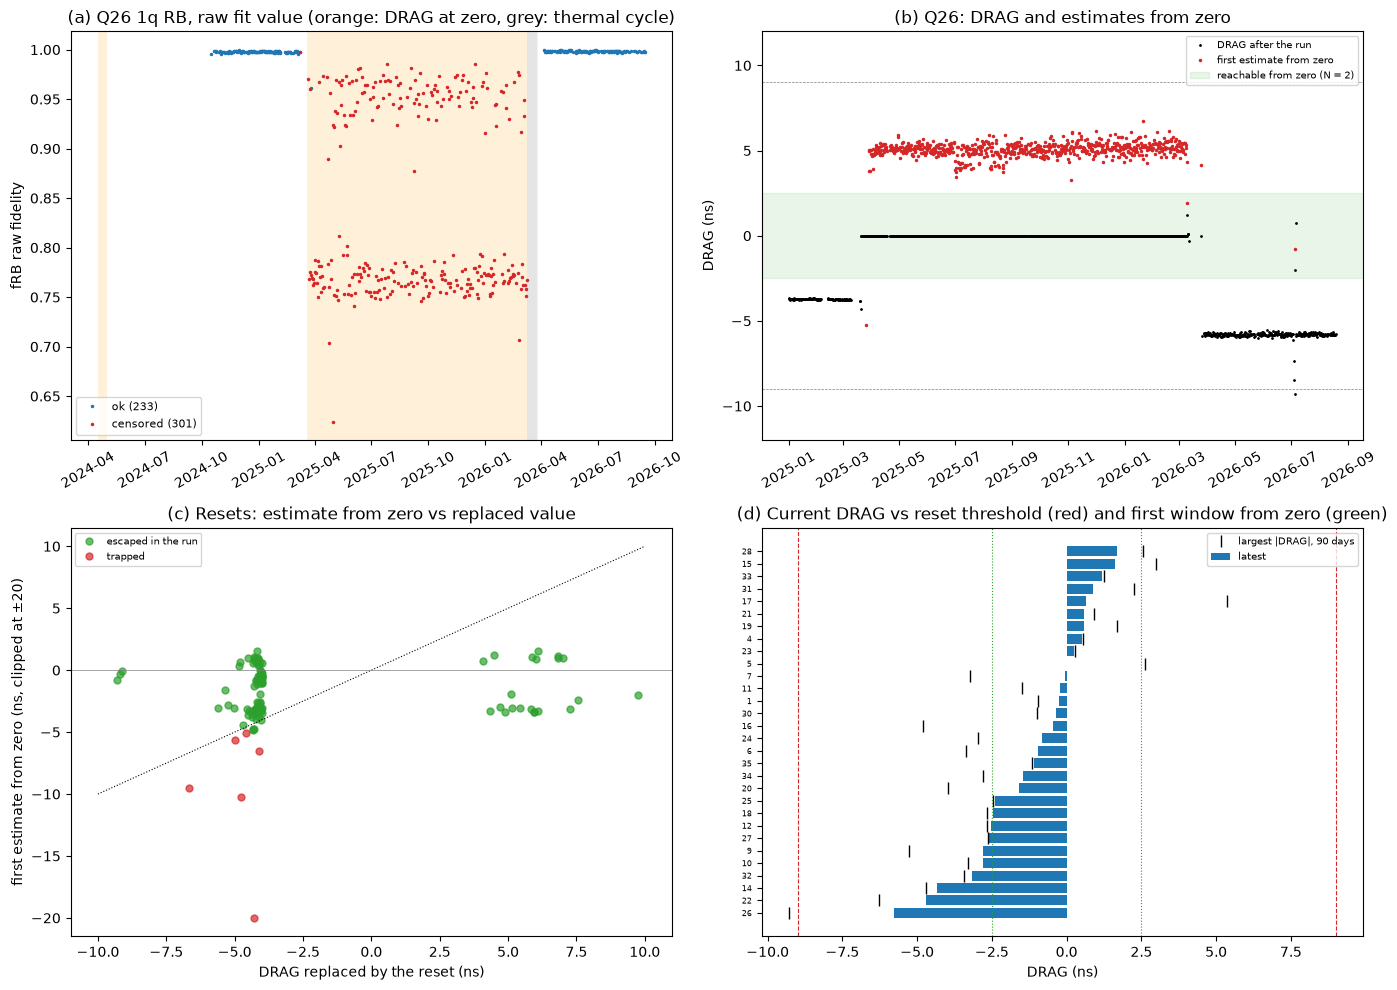

In [12]:
# The figure follows the qubit of the longest stuck episode
q0 = int(r0.qubit)
cyc = next(i.period for i in periods.INCIDENTS if "thermal" in i.what)
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# (a) Raw fRB on that qubit, with its DRAG-zero episodes and the thermal cycle shaded
a = ax[0, 0]
for r in EP[EP["qubit"] == q0].itertuples():
    a.axvspan(r.start, r.end, color="orange", alpha=0.15, lw=0)
a.axvspan(*cyc, color="grey", alpha=0.2, lw=0)

x = rb[(rb["element"] == str(q0)) & rb["usable"]]
for cl, col in [("ok", "tab:blue"), ("censored", "tab:red")]:
    gq = x[x["cls"] == cl]
    a.plot(gq["t"], gq["value_u"], ".", ms=3, color=col, label=f"{cl} ({len(gq)})")

a.set(
    ylabel="fRB raw fidelity",
    title=f"(a) Q{q0} 1q RB, raw fit value (orange: DRAG at zero, grey: thermal cycle)",
)
a.tick_params(axis="x", rotation=30)
a.legend(fontsize=8, loc="lower left")

# (b) DRAG after each run since 2025, and the first estimates from zero
a = ax[0, 1]
qr = RUN[(RUN["qubit"] == q0) & (RUN["start"] >= "2025-01-01")]
a.plot(qr["start"], qr["new"] * NS, ".", ms=2, color="k", label="DRAG after the run")
f = qr[qr["start_val"] == 0]
a.plot(f["start"], f["e0"] * NS, ".", ms=3, color="tab:red", label="first estimate from zero")

# Reset threshold (dashed) and the window reachable from zero (green)
for s in (-9, 9):
    a.axhline(s, color="grey", lw=0.5, ls="--")
a.axhspan(-2.5, 2.5, color="tab:green", alpha=0.1, label="reachable from zero (N = 2)")

a.set(ylim=(-12, 12), ylabel="DRAG (ns)", title=f"(b) Q{q0}: DRAG and estimates from zero")
a.tick_params(axis="x", rotation=30)
a.legend(fontsize=7)

# (c) Every reset: first estimate from zero against the value it replaced
a = ax[1, 0]
for o, col in [("escaped in the run", "tab:green"), ("trapped", "tab:red")]:
    x = RS[RS["outcome"] == o]
    a.plot(x["replaced"], x["e0"].clip(-20, 20), "o", ms=5, color=col, label=o, alpha=0.7)
a.plot([-10, 10], [-10, 10], "k:", lw=0.8)
a.axhline(0, color="grey", lw=0.5)

a.set(
    xlabel="DRAG replaced by the reset (ns)",
    ylabel="first estimate from zero (ns, clipped at ±20)",
    title="(c) Resets: estimate from zero vs replaced value",
)
a.legend(fontsize=7)

# (d) Latest DRAG per qubit and its 90-day extreme, against both thresholds
a = ax[1, 1]
x = RK.sort_values("latest")
a.barh(x["qubit"].astype(str), x["latest"], color="tab:blue", label="latest")
a.plot(
    np.sign(x["latest"]) * x["max_abs_90d"],
    x["qubit"].astype(str),
    "k|",
    ms=8,
    label="largest |DRAG|, 90 days",
)
for s in (-9, 9):
    a.axvline(s, color="tab:red", lw=0.8, ls="--")
for s in (-2.5, 2.5):
    a.axvline(s, color="tab:green", lw=0.8, ls=":")

a.set(
    xlabel="DRAG (ns)",
    title="(d) Current DRAG vs reset threshold (red) and first window from zero (green)",
)
a.tick_params(axis="y", labelsize=6)
a.legend(fontsize=7)

fig.tight_layout()
fig.savefig(FIG / "d3b_drag_trap.png", dpi=130)
plt.show()

## Conclusion

**Verdict: holds, with a refined cause.** Every trap starts with a reset to zero. From zero, the routine's estimates of DRAG are unreliable, and they fall outside the first window run after run. Stuck episodes take the qubit's 1q RB from mostly ok to almost all censored. All six traps started under the old code, whose 4 ns threshold was close to these qubits' normal DRAG. The current code resets only above 9 ns, but it still can't return a reset qubit in one step, and it didn't release Q26 from its trap. Keeping or clipping the value instead of resetting it would avoid both problems.

| Result | Status |
|---|---|
| The log has 17 episodes on 7 qubits, and DS2 agrees. The longest are Q13 (silent, 515.9 days) and Q26 (stuck, 354.3 days), both from the 2025-03-20 rollback (section 1). | Confirmed |
| Stuck episodes take the qubit's fRB ok share to 0.003 or less, and it recovers after. The silent Q13 episode costs little (section 2.1). | Holds |
| T1 holds. Q26's T2 falls but keeps falling after the episode. fRO rises a little in the stuck episodes (section 2.2). | Holds in part |
| fCX ok share falls on the couplings of Q16 and Q26, not on those of Q13 and Q27 (section 2.3). | Holds for Q16 and Q26 |
| The replay matches the log exactly. The reset thresholds are 4 ns (old code) and 9 ns (new code) (section 3.1). | Confirmed |
| All 6 traps start under the old code, 5 of them from values within 1.2 ns of its threshold. Q26's trap lasts almost a year under the new code (section 3.2). | Holds |
| Estimates from zero overshoot at $N = 1$, have the wrong sign on Q26 at $N = 2$, and undershoot on escaped resets (section 3.3). | Holds |
| A wider first window would be reset again on all 6 traps. Keeping the replaced value would likely have let the routine continue (section 4). | No reset is the candidate change |
| Under the current code, a correct estimate after a reset is always rejected. Q26 reached 9.29 ns in 2026-07, and Q22 trends to 9 ns in about a year (section 5). | Risk remains |
| Heavy fRB censoring on other qubits doesn't come from a frozen DRAG (section 6). | Holds |